# Check out the time embeddings etc in MeshFlow

# reference copy of definitions (out of context)
```
class Timesteps(nn.Module):
    """Sinusoidal timestep embedding (sin/cos over frequency bands)."""

    def __init__(
        self,
        num_channels: int,
        downscale_freq_shift: float = 0.0,
        scale: int = 1000,
        max_period: int = 10000,
    ):
        super().__init__()
        self.num_channels = num_channels
        self.downscale_freq_shift = downscale_freq_shift
        self.scale = scale
        self.max_period = max_period

        half_dim = num_channels // 2
        exponent = -math.log(max_period) * torch.arange(
            start=0, end=half_dim, dtype=torch.float32
        )
        exponent = exponent / (half_dim - downscale_freq_shift)
        self.register_buffer("freq_embedding", torch.exp(exponent), persistent=False)
    

    def forward(self, timesteps: torch.Tensor) -> torch.Tensor:
        """Embed 1D timestep tensor (shape [B]) to [B, num_channels]."""
        assert len(timesteps.shape) == 1, "Timesteps should be a 1d-array"
        if self.scale == 1000:
            assert timesteps.max() <= 1.0, "Timesteps should be in the range [0, 1]"
        emb = timesteps[:, None].float() * self.freq_embedding[None, :].to(
            timesteps.device
        )
        emb = self.scale * emb
        emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)
        if self.num_channels % 2 == 1:
            emb = torch.nn.functional.pad(emb, (0, 1, 0, 0))
        return emb


class TimestepEmbedder(nn.Module):
    """Embed scalar timesteps to a vector [B, out_size] for AdaLN (no extra sequence token)."""

    def __init__(
        self,
        hidden_size,
        frequency_embedding_size=256,
        cond_proj_dim=None,
        out_size=None,
    ):
        super().__init__()
        if out_size is None:
            out_size = hidden_size
        self.mlp = nn.Sequential(
            nn.Linear(hidden_size, frequency_embedding_size, bias=True),
            nn.GELU(),
            nn.Linear(frequency_embedding_size, out_size, bias=True),
        )
        self.frequency_embedding_size = frequency_embedding_size

        if cond_proj_dim is not None:
            self.cond_proj = nn.Linear(cond_proj_dim, hidden_size, bias=False)

        self.time_embed = Timesteps(hidden_size)

    def forward(self, t: torch.Tensor, condition: Optional[torch.Tensor] = None) -> torch.Tensor:
        """Return timestep embedding [B, out_size]."""
        t_freq = self.time_embed(t).type(self.mlp[0].weight.dtype)

        if condition is not None:
            t_freq = t_freq + self.cond_proj(condition)

        return self.mlp(t_freq)
```

In [ ]:

class Timesteps(nn.Module):
    """Sinusoidal timestep embedding (sin/cos over frequency bands)."""

    def __init__(
        self,
        num_channels: int,
        downscale_freq_shift: float = 0.0,
        scale: int = 1000,
        max_period: int = 10000,
    ):
        super().__init__()
        self.num_channels = num_channels
        self.downscale_freq_shift = downscale_freq_shift
        self.scale = scale
        self.max_period = max_period

        half_dim = num_channels // 2
        exponent = -math.log(max_period) * torch.arange(
            start=0, end=half_dim, dtype=torch.float32
        )
        exponent = exponent / (half_dim - downscale_freq_shift)
        self.register_buffer("freq_embedding", torch.exp(exponent), persistent=False)

    def forward(self, timesteps: torch.Tensor) -> torch.Tensor:
        """Embed 1D timestep tensor (shape [B]) to [B, num_channels]."""
        assert len(timesteps.shape) == 1, "Timesteps should be a 1d-array"
        if self.scale == 1000:
            assert timesteps.max() <= 1.0, "Timesteps should be in the range [0, 1]"
        emb = timesteps[:, None].float() * self.freq_embedding[None, :].to(
            timesteps.device
        )
        emb = self.scale * emb
        emb = torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)
        if self.num_channels % 2 == 1:
            emb = torch.nn.functional.pad(emb, (0, 1, 0, 0))
        return emb



tensor([  -0.0000,   -9.2103,  -18.4207,  -27.6310,  -36.8414,  -46.0517,
         -55.2620,  -64.4724,  -73.6827,  -82.8931,  -92.1034, -101.3137,
        -110.5241, -119.7344, -128.9448, -138.1551, -147.3654, -156.5758,
        -165.7861, -174.9965, -184.2068, -193.4171, -202.6275, -211.8378,
        -221.0482, -230.2585, -239.4689, -248.6792, -257.8895, -267.0999,
        -276.3102, -285.5206])
[0 : half_dim] ticks
tensor([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11., 12., 13.,
        14., 15., 16., 17., 18., 19., 20., 21., 22., 23., 24., 25., 26., 27.,
        28., 29., 30., 31.])
scale by neg log max_period
tensor([  -0.0000,   -9.2103,  -18.4207,  -27.6310,  -36.8414,  -46.0517,
         -55.2620,  -64.4724,  -73.6827,  -82.8931,  -92.1034, -101.3137,
        -110.5241, -119.7344, -128.9448, -138.1551, -147.3654, -156.5758,
        -165.7861, -174.9965, -184.2068, -193.4171, -202.6275, -211.8378,
        -221.0482, -230.2585, -239.4689, -248.6792, -257.8895, -267.0

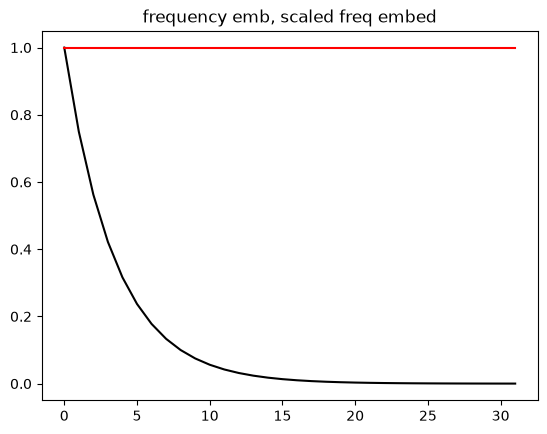

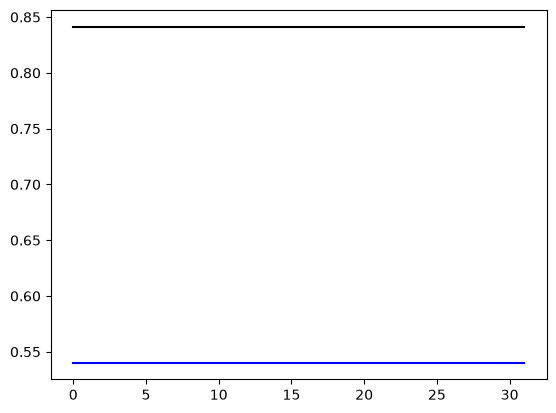

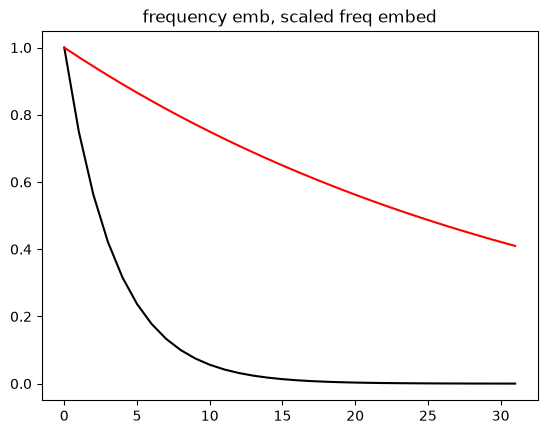

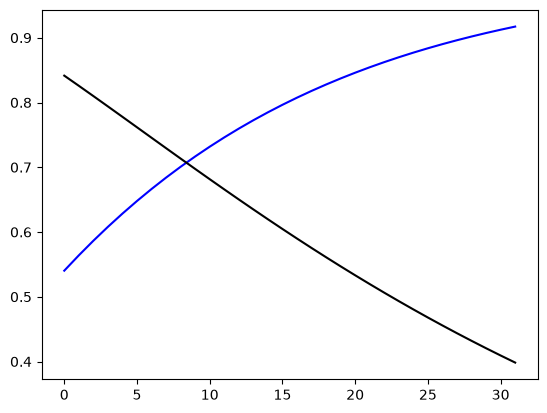

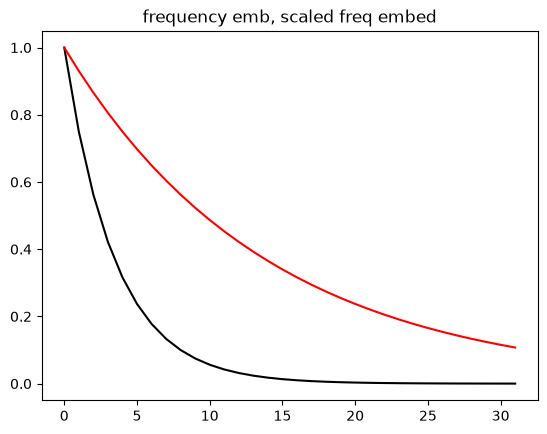

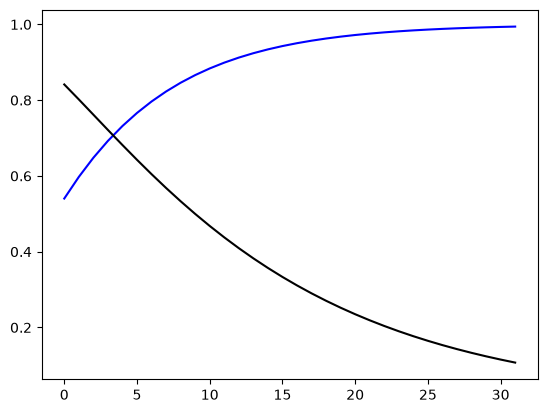

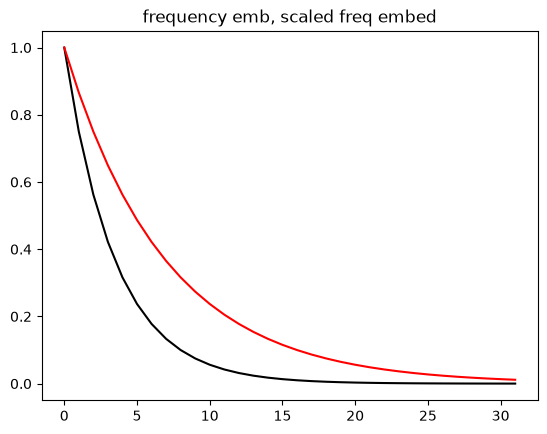

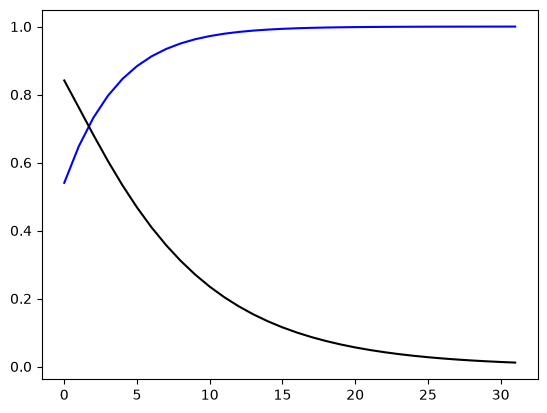

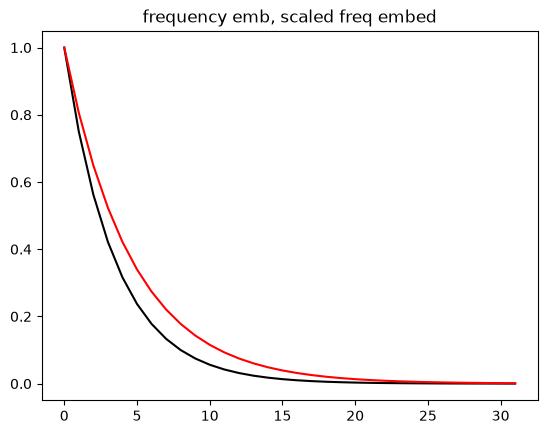

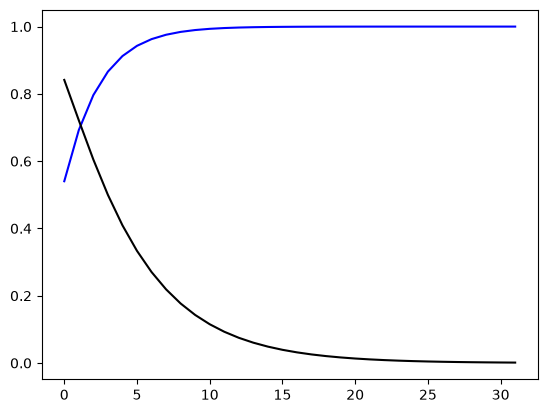

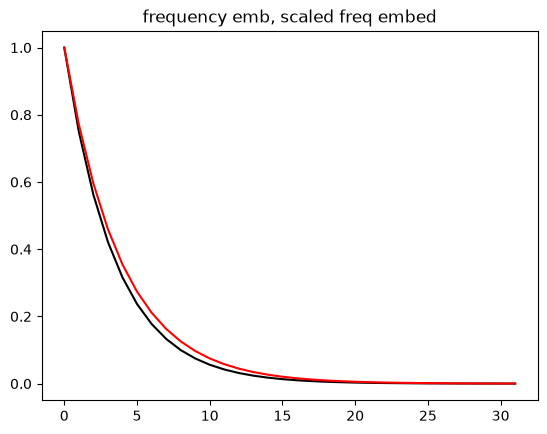

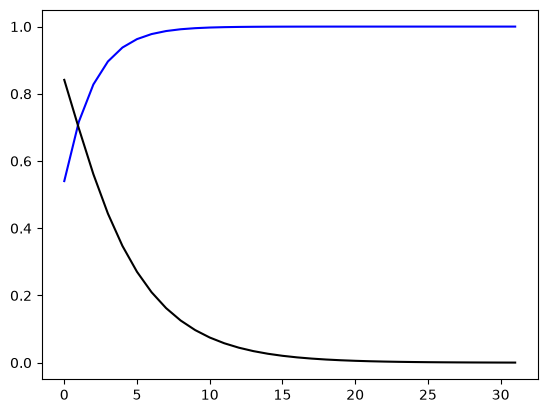

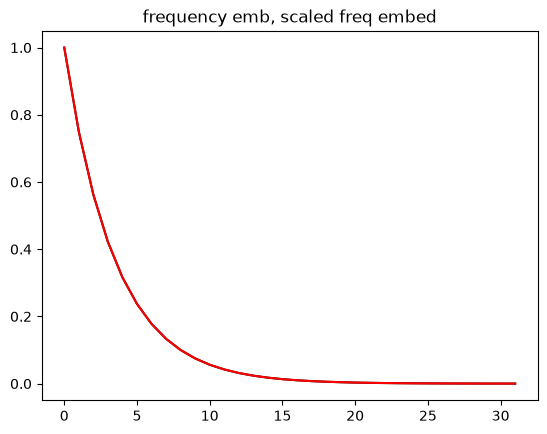

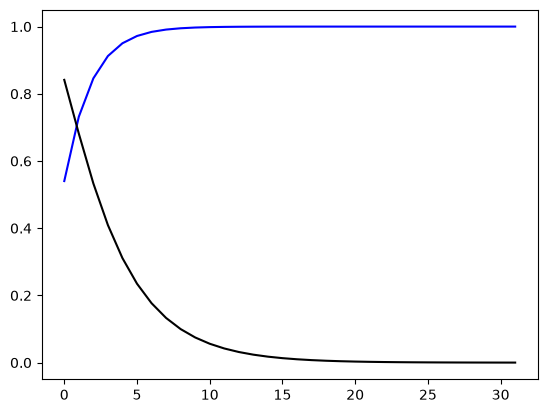

In [21]:
import math
import torch

num_channels = 64
downscale_freq_shift = 0.0
scale = 1000
max_period = 10000

half_dim = num_channels // 2
exponent = -math.log(max_period) * torch.arange(
    start=0, end=half_dim, dtype=torch.float32
)
print(exponent)

print("[0 : half_dim] ticks")
print(torch.arange(start=0, end=half_dim, dtype=torch.float32)) 

print("scale by neg log max_period")
print(-math.log(max_period) * torch.arange(start=0, end=half_dim, dtype=torch.float32))

print("scale to the range (0:1) (when downscale_freq_shift=0)")
exponent = exponent / (half_dim - downscale_freq_shift)
print(exponent)

print("frequency_emb:")
frequency_emb = torch.exp(exponent)
print(frequency_emb)

import matplotlib.pyplot as plt

def viz(scalar=1.0):
    plt.figure()
    plt.title('frequency emb, scaled freq embed')
    plt.plot(torch.exp(exponent), color='k')
    plt.plot(torch.exp(scalar * exponent), color='r')

    plt.figure()
    plt.plot(torch.cos(torch.exp(scalar * exponent)), color='b')
    plt.plot(torch.sin(torch.exp(scalar * exponent)), color='k')

viz(0.0)
viz(0.1)
viz(0.25)
viz(0.5)
viz(0.75)
viz(0.9)
viz(1.0)




tensor([1.0000e+00, 8.6399e-01, 7.4648e-01, 6.4495e-01, 5.5723e-01, 4.8144e-01,
        4.1596e-01, 3.5938e-01, 3.1050e-01, 2.6827e-01, 2.3178e-01, 2.0026e-01,
        1.7302e-01, 1.4949e-01, 1.2915e-01, 1.1159e-01, 9.6411e-02, 8.3298e-02,
        7.1969e-02, 6.2180e-02, 5.3723e-02, 4.6416e-02, 4.0103e-02, 3.4648e-02,
        2.9936e-02, 2.5864e-02, 2.2346e-02, 1.9307e-02, 1.6681e-02, 1.4412e-02,
        1.2452e-02, 1.0758e-02, 9.2951e-03, 8.0309e-03, 6.9386e-03, 5.9948e-03,
        5.1795e-03, 4.4750e-03, 3.8664e-03, 3.3405e-03, 2.8861e-03, 2.4936e-03,
        2.1544e-03, 1.8614e-03, 1.6082e-03, 1.3895e-03, 1.2005e-03, 1.0372e-03,
        8.9615e-04, 7.7426e-04, 6.6895e-04, 5.7797e-04, 4.9936e-04, 4.3144e-04,
        3.7276e-04, 3.2206e-04, 2.7826e-04, 2.4041e-04, 2.0771e-04, 1.7946e-04,
        1.5505e-04, 1.3396e-04, 1.1574e-04, 1.0000e-04])


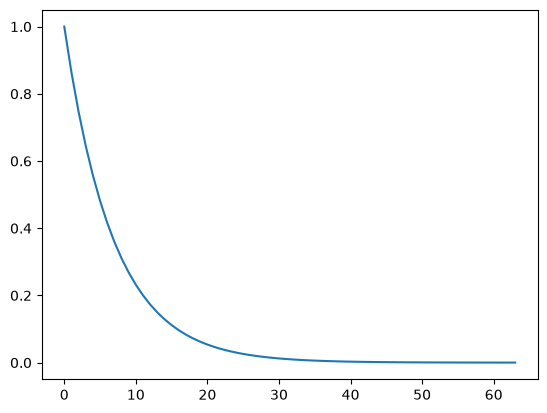

In [ ]:
# compare the definition in FlowMatching-DiT

import torch
import math
import matplotlib.pyplot as plt

dim = 128
half_dim = dim // 2
freqs = torch.exp(-math.log(10000) * torch.arange(half_dim) / (half_dim - 1))
print(freqs)

plt.figure()
plt.plot(freqs)